In [ ]:
main_dir = 'PATH-TO-MAIN-DIRECTORY'

In [ ]:
from tqdm import tqdm
import xarray as xr
import pandas as pd
import numpy as np
import itertools
import warnings
import torch
import glob
import sys
import os
ocean = 'oras5'
atmos = 'era5'
os.environ['ocean'] = ocean.upper()
os.environ['atmos'] = atmos.upper()

sys.path.append(os.path.join(main_dir, 'library'))
from atmocean.macros import ALL_DRIVERS
from atmocean.utils import deaggregate_systems
# filter out nan warnings
warnings.filterwarnings('ignore')
os.system('hostname')

n165.cmn.juno.cmcc.scc


0

In [ ]:
start_year = 1993 # first available year
end_year = 2017   # 25 years of climatology
years = np.arange(start_year, end_year+1)
res = '025'

dataset_src = os.path.join(main_dir, f'data/datasets/all_{res}_deg')
clm_dst = os.path.join(main_dir, f'data/datasets/climatology/climatology_{res}-from_{start_year}_to_{end_year}.zarr')
clm_forecast_dst = os.path.join(main_dir, f'data/forecasts/climatology_{res}-from_{start_year}_to_{end_year}.zarr')

# select a climatology window size
window_size = 0 # 1-day
# get date range for a leap year (e.g., 2000)
dates = pd.date_range('2000-01-01', '2000-12-31', freq='1D')
# get total number of days in a year
n = len(dates)
# show dates
dates

DatetimeIndex(['2000-01-01', '2000-01-02', '2000-01-03', '2000-01-04',
               '2000-01-05', '2000-01-06', '2000-01-07', '2000-01-08',
               '2000-01-09', '2000-01-10',
               ...
               '2000-12-22', '2000-12-23', '2000-12-24', '2000-12-25',
               '2000-12-26', '2000-12-27', '2000-12-28', '2000-12-29',
               '2000-12-30', '2000-12-31'],
              dtype='datetime64[ns]', length=366, freq='D')

In [3]:
if not os.path.exists(clm_dst):
    # get list of day of the year
    days_of_year = [i for i in range(n)]
    a3d_list, a2d_list, o3d_list, o2d_list = [],[],[],[]
    # init the iterable
    iterable = tqdm(zip(dates, days_of_year), desc='Day of year', total=n)
    # iterate over each date
    for date, day_of_year in iterable:
        # get all the dates in the window size
        window_dates = pd.date_range(start=date-pd.DateOffset(days=window_size), end=date+pd.DateOffset(days=window_size))
        # get all filenames from dataset
        fnames = []
        for year in years:
            fnames += list(sorted(
                itertools.chain(
                    *[glob.glob(os.path.join(dataset_src, f'{year}{wdate.month:02d}{wdate.day:02d}.npy')) for wdate in window_dates]
                )
            ))
        # open the dataset
        data = np.stack([np.load(fname, mmap_mode='r+') for fname in fnames], axis=0)
        # compute the mean
        data = np.nanmean(data, axis=0)
        # separate each system
        a3d, a2d, o3d, o2d = deaggregate_systems(
            torch.as_tensor(data).unsqueeze(1).unsqueeze(0), 
            ALL_DRIVERS['input']['atmos']['fields_3d'], 
            ALL_DRIVERS['input']['atmos']['fields_2d'], 
            ALL_DRIVERS['input']['ocean']['fields_3d'], 
            ALL_DRIVERS['input']['ocean']['fields_2d'], 
        )
        # convert to numpy
        a3d, a2d, o3d, o2d = (
            a3d[0,:,0].numpy(),
            a2d[0,:,0,0].numpy(),
            o3d[0,:,0].numpy(),
            o2d[0,:,0,0].numpy(),
        )
        # add to the data lists
        a3d_list.append(a3d)
        a2d_list.append(a2d)
        o3d_list.append(o3d)
        o2d_list.append(o2d)

In [4]:
if not os.path.exists(clm_dst):
    # stack together every system climatology
    a3d_stacked = np.stack(a3d_list)
    a2d_stacked = np.stack(a2d_list)
    o3d_stacked = np.stack(o3d_list)
    o2d_stacked = np.stack(o2d_list)
    # build the climatology dataset
    clm = xr.Dataset(
        data_vars={
            **{field: (('time', 'level','latitude','longitude'), a3d_stacked[:,i]) for i,field in enumerate(ALL_DRIVERS['input']['atmos']['fields_3d'])}, 
            **{field: (('time', 'latitude','longitude'), a2d_stacked[:,i]) for i,field in enumerate(ALL_DRIVERS['input']['atmos']['fields_2d'])}, 
            **{field: (('time', 'depth','latitude','longitude'), o3d_stacked[:,i]) for i,field in enumerate(ALL_DRIVERS['input']['ocean']['fields_3d'])}, 
            **{field: (('time', 'latitude','longitude'), o2d_stacked[:,i]) for i,field in enumerate(ALL_DRIVERS['input']['ocean']['fields_2d'])}, 
        }, 
        coords={
            'depth': ALL_DRIVERS['depths'], 
            'level': ALL_DRIVERS['levels'], 
            'latitude': np.arange(-90, 90.25, 0.25)[::-1], # np.array(list(reversed(np.arange(181.0) - 90))), 
            'longitude': np.arange(0, 360, 0.25), # np.arange(360.0), 
            'time': dates, 
        }
    )

In [5]:
if not os.path.exists(clm_dst):
    # clm.chunk(chunks={}).to_zarr(clm_dst)
    clm.chunk(chunks={
        'time': 1,
        'latitude': -1,
        'longitude': -1,
        'depth': -1,
        'level': -1,
    }).to_zarr(clm_dst, zarr_format=2)
clm = xr.open_zarr(clm_dst, chunks={})
clm

<xarray.Dataset> Size: 167GB
Dimensions:                  (time: 366, latitude: 721, longitude: 1440,
                              level: 7, depth: 14)
Coordinates:
  * time                     (time) datetime64[ns] 3kB 2000-01-01 ... 2000-12-31
  * latitude                 (latitude) float64 6kB 90.0 89.75 ... -89.75 -90.0
  * longitude                (longitude) float64 12kB 0.0 0.25 ... 359.5 359.8
  * level                    (level) int64 56B 300 500 600 700 850 925 1000
  * depth                    (depth) float64 112B 0.5058 1.556 ... 5.089e+03
Data variables: (12/22)
    10m_u_component_of_wind  (time, latitude, longitude) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    10m_v_component_of_wind  (time, latitude, longitude) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    2m_dewpoint_temperature  (time, latitude, longitude) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    2m_temperature           (time, latitude, longitude) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    geopotential             (time, level, latitude, longitude) float32 11GB dask.array<chunksize=(1, 7, 721, 1440), meta=np.ndarray>
    mean_sea_level_pressure  (time, latitude, longitude) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
    ...                       ...
    u_component_of_wind      (time, level, latitude, longitude) float32 11GB dask.array<chunksize=(1, 7, 721, 1440), meta=np.ndarray>
    uo_oras                  (time, depth, latitude, longitude) float32 21GB dask.array<chunksize=(1, 14, 721, 1440), meta=np.ndarray>
    v_component_of_wind      (time, level, latitude, longitude) float32 11GB dask.array<chunksize=(1, 7, 721, 1440), meta=np.ndarray>
    vertical_velocity        (time, level, latitude, longitude) float32 11GB dask.array<chunksize=(1, 7, 721, 1440), meta=np.ndarray>
    vo_oras                  (time, depth, latitude, longitude) float32 21GB dask.array<chunksize=(1, 14, 721, 1440), meta=np.ndarray>
    zos_oras                 (time, latitude, longitude) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>

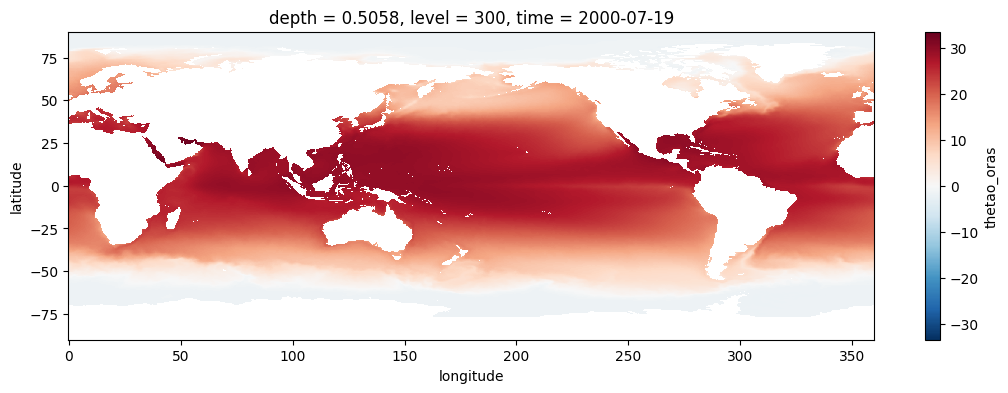

In [6]:
clm.isel(time=200, level=0, depth=0)['thetao_oras'].plot(figsize=(13,4))

In [7]:
drivers = ALL_DRIVERS['input']['ocean']['fields_3d'] + ALL_DRIVERS['input']['ocean']['fields_2d']

In [8]:
lead_times = [0, 10, 20, 30, 40, 50, 60]

In [9]:
# number of forecasts
forecast_horizon = 60
# get all the prediction timedeltas
prediction_timedelta = pd.to_timedelta(lead_times, unit='days') # pd.timedelta_range(start=0, periods=forecast_horizon+1, freq='1D')
# copy the climatology
clm_fc = clm.copy()
# set only the drivers
clm_fc = clm_fc[drivers]
# expand the dimensions 
clm_fc = clm_fc.expand_dims(dim=dict(prediction_timedelta=prediction_timedelta[0:1]), axis=1)
clm_fc.chunk(chunks={
    'prediction_timedelta': 1,
    'time': 1,
    'latitude': -1,
    'longitude': -1,
    'depth': -1,
}).to_zarr(
    clm_forecast_dst,
    zarr_format=2,
)

In [10]:
for i,lt in tqdm(enumerate(lead_times[1:]), total=len(lead_times[1:])):
    clmi = clm.roll(shifts=dict(time=-lt))[drivers]
    clmi['time'] = clm.time.values
    clmi = clmi.expand_dims(dim=dict(prediction_timedelta=pd.to_timedelta(prediction_timedelta[1:][i:i+1], unit='days')), axis=1)
    clmi = clmi.chunk(chunks={
        'prediction_timedelta': 1,
        'time': 1,
        'latitude': -1,
        'longitude': -1,
        'depth': -1,
    }).to_zarr(
        clm_forecast_dst,
        append_dim='prediction_timedelta',
        zarr_format=2,
    )

  0%|          | 0/6 [00:00<?, ?it/s]

100%|██████████| 6/6 [12:13<00:00, 122.19s/it]


In [11]:
clm_fc = xr.open_zarr(clm_forecast_dst, chunks={})

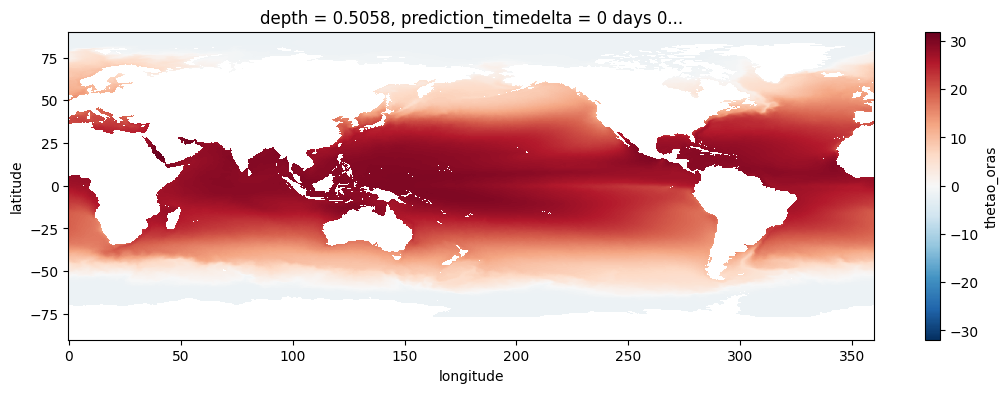

In [13]:
clm_fc.isel(time=300, prediction_timedelta=0, depth=0)['thetao_oras'].plot(figsize=(13,4))

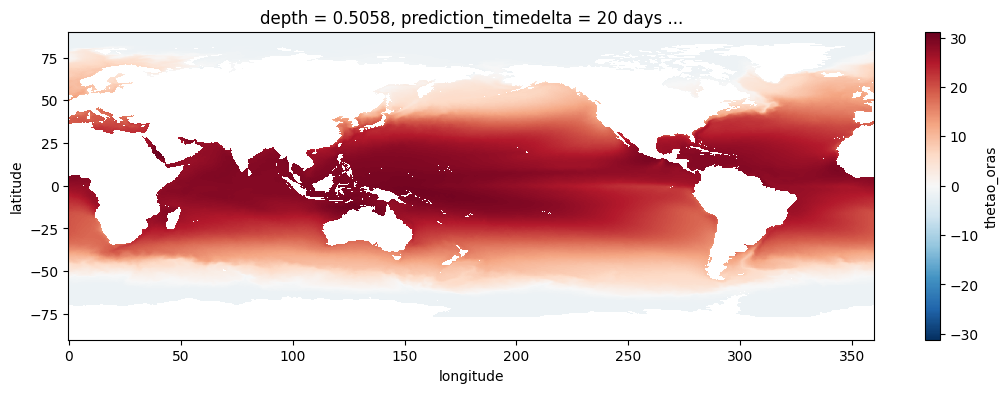

In [14]:
clm_fc.isel(time=300, prediction_timedelta=2, depth=0)['thetao_oras'].plot(figsize=(13,4))

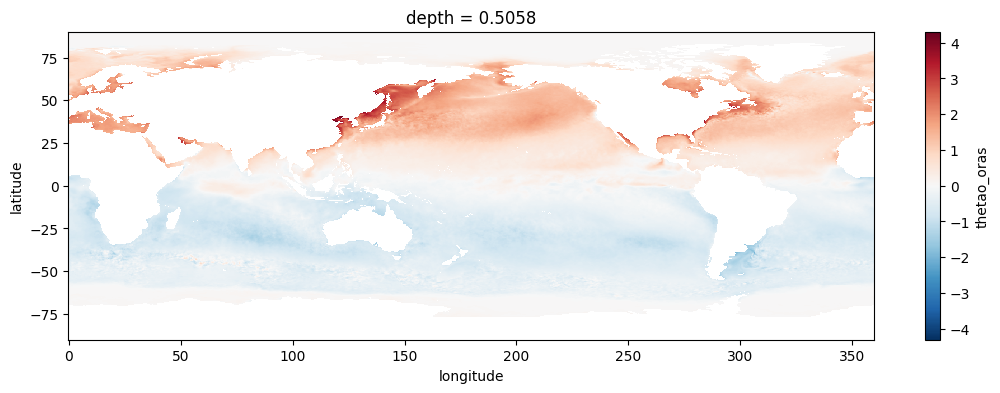

In [15]:
(
    clm_fc.isel(time=300, prediction_timedelta=0, depth=0)['thetao_oras']
    -
    clm_fc.isel(time=298, prediction_timedelta=2, depth=0)['thetao_oras']
).plot(figsize=(13,4))